# The Hatch C2 · Regresión y clasificación

Versión breve: preparación → train/test → entrenamiento y validación cruzada →
evaluación → interpretación. Ejecutar en VS Code con el kernel **.venv** y **Run All**.
Ver `README.md` para instalar dependencias.

| Datos | Fuente |
| --- | --- |
| `data/housing.csv` | [California Housing Prices · Kaggle](https://www.kaggle.com/datasets/camnugent/california-housing-prices), aportado al proyecto |
| `data/WA_Fn-UseC_-Telco-Customer-Churn.csv` | [Telco Customer Churn · BlastChar · Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), descarga directa, versión 1 |

Antecedente: `C1_The_hatch/notebooks/01_viviendas.ipynb`. Churn es un dataset de
muestra de IBM según Kaggle. Ambos CSV se leen localmente, sin descargas.


## 1. Configuración

Compartimos una función de preparación para ambas misiones: numéricas con mediana
y escalado; categóricas con moda y one-hot. Cada fold ajusta su propio Pipeline:
ni la imputación ni el escalado aprenden del test. Usamos 80/20 y semilla 42.


In [1]:
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.metrics import (root_mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

warnings.filterwarnings('error', category=ConvergenceWarning)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/housing.csv').exists())
print('Python:', sys.executable)


def pipeline(X, modelo):
    numericas = X.select_dtypes('number').columns
    preparar = ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numericas),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
            OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
         X.columns.difference(numericas)),
    ])
    return Pipeline([('preparar', preparar), ('modelo', modelo)])


Python: C:\Users\Guillermo Lopez\Desktop\01_SI_O_SI_BACKUP\04_Proyectos\Codepro\The_hatch\C2_The_hatch\.venv\Scripts\python.exe


## 2. Housing · Recordatorio del EDA y preparación

El EDA anterior detectó dormitorios faltantes, asociación ingreso/precio y un tope
en el valor objetivo. Verificamos estos puntos y conservamos todas las filas,
incluidos extremos y topes. No reutilizamos el subconjunto curado ni la imputación
global del EDA: cambiarían la población o filtrarían información a la evaluación.

Una fila es una **zona censal**, no una casa. Predecimos `median_house_value` en
**USD de 1990**. `median_income` está escalado. Usamos las nueve columnas predictoras
originales para mantener el código breve; los ratios explorados en C1 son opcionales.


In [2]:
housing = pd.read_csv(ROOT / 'data/housing.csv')
display(housing.head(3))
display(housing.isna().sum().rename('faltantes').to_frame())
print('Dimensiones:', housing.shape, '| Duplicados:', housing.duplicated().sum())
print('Máximo y zonas en él:', housing.median_house_value.max(),
      housing.median_house_value.eq(housing.median_house_value.max()).sum())
assert housing.median_house_value.notna().all()
Xh, yh = housing.drop(columns='median_house_value'), housing.median_house_value
Xh_train, Xh_test, yh_train, yh_test = train_test_split(Xh, yh, test_size=.2, random_state=42)
print('Train/test:', len(Xh_train), len(Xh_test))
print('Correlación ingreso/precio en train:', Xh_train.median_income.corr(yh_train).round(3))


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY


,faltantes
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


Dimensiones: (20640, 10) | Duplicados: 0
Máximo y zonas en él: 500001.0 965
Train/test: 16512 4128
Correlación ingreso/precio en train: 0.691


### Entrenamiento: media, lineal, Ridge y Lasso

El baseline predice la media. Ridge penaliza coeficientes con L2; Lasso usa L1 y
puede llevarlos a cero. Elegimos `alpha` y modelo por **menor RMSE de CV en train**,
con cinco folds comunes. La regularización no garantiza mejorar.

RMSE = raíz del promedio de errores cuadrados; penaliza más los errores grandes.
MAE = promedio de errores absolutos. Ambos están en USD de 1990; R² no tiene unidad
y puede ser negativo. El test queda reservado hasta fijar el ganador por CV.


In [3]:
grid_h = [{'modelo': [DummyRegressor()]}, {'modelo': [LinearRegression()]},
          {'modelo': [Ridge()], 'modelo__alpha': [1, 10, 100]},
          {'modelo': [Lasso(max_iter=50000)], 'modelo__alpha': [10, 100, 1000]}]
busqueda_h = GridSearchCV(pipeline(Xh_train, LinearRegression()), grid_h,
    scoring='neg_root_mean_squared_error', cv=KFold(5, shuffle=True, random_state=42),
    error_score='raise').fit(Xh_train, yh_train)
cv_h = pd.DataFrame({'modelo': [type(p['modelo']).__name__ for p in busqueda_h.cv_results_['params']],
    'RMSE_CV': -busqueda_h.cv_results_['mean_test_score'],
    'parametros': busqueda_h.cv_results_['params']})
cv_h = cv_h.loc[cv_h.groupby('modelo').RMSE_CV.idxmin()].set_index('modelo')
ganador_h = type(busqueda_h.best_estimator_['modelo']).__name__
display(cv_h)
print('Elegido por CV:', ganador_h)


,RMSE_CV,parametros
modelo,,
DummyRegressor,115617.185265,{'modelo': DummyRegressor()}
Lasso,68599.872750,"{'modelo': Lasso(max_iter=50000), 'modelo__alp..."
LinearRegression,68604.162955,{'modelo': LinearRegression()}
Ridge,68594.885018,"{'modelo': Ridge(), 'modelo__alpha': 1}"


Elegido por CV: Ridge


### Evaluación e interpretación

Comparamos cada familia con sus parámetros elegidos en train; no cambiamos al
ganador por los resultados de test. El RMSE de train ayuda a observar la brecha de
ajuste. En los residuos, real − predicho positivo significa subestimación.


,RMSE_train,RMSE_test,MAE_test,R2
modelo,,,,
DummyRegressor,115619.125,114485.635,90606.855,-0.000
Lasso,68437.030,70070.581,50680.018,0.625
LinearRegression,68433.937,70059.193,50670.489,0.625
Ridge,68435.253,70067.481,50678.107,0.625


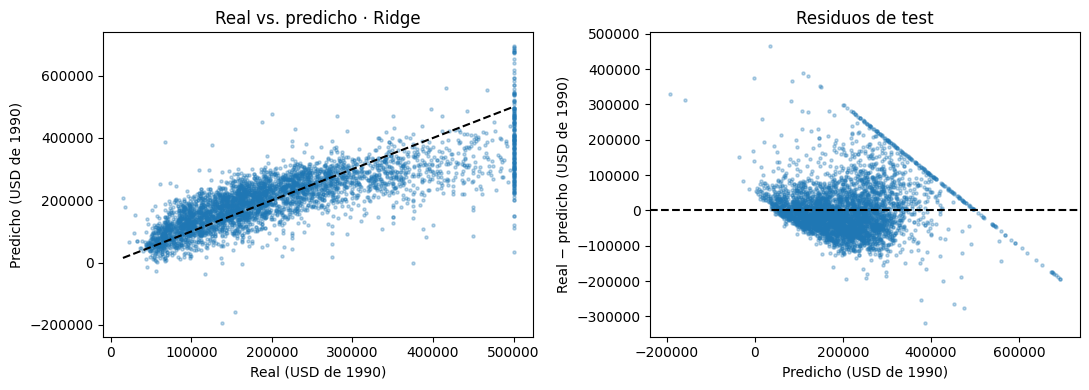

In [4]:
modelos_h, filas_h = {}, []
for nombre, fila in cv_h.iterrows():
    modelo = clone(busqueda_h.estimator).set_params(**fila.parametros).fit(Xh_train, yh_train)
    modelos_h[nombre] = modelo
    pred = modelo.predict(Xh_test)
    filas_h.append([nombre, root_mean_squared_error(yh_train, modelo.predict(Xh_train)),
                   root_mean_squared_error(yh_test, pred), mean_absolute_error(yh_test, pred),
                   r2_score(yh_test, pred)])
test_h = pd.DataFrame(filas_h, columns=['modelo', 'RMSE_train', 'RMSE_test', 'MAE_test', 'R2']).set_index('modelo')
display(test_h.round(3))
pred_h = modelos_h[ganador_h].predict(Xh_test)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(yh_test, pred_h, s=5, alpha=.3)
ax[0].plot([yh_test.min(), yh_test.max()], [yh_test.min(), yh_test.max()], 'k--')
ax[0].set(title=f'Real vs. predicho · {ganador_h}', xlabel='Real (USD de 1990)', ylabel='Predicho (USD de 1990)')
ax[1].scatter(pred_h, yh_test - pred_h, s=5, alpha=.3)
ax[1].axhline(0, color='black', linestyle='--')
ax[1].set(title='Residuos de test', xlabel='Predicho (USD de 1990)', ylabel='Real − predicho (USD de 1990)')
fig.tight_layout(); plt.show(); plt.close(fig)


In [5]:
coef_h = pd.DataFrame({nombre: pd.Series(modelos_h[nombre]['modelo'].coef_,
    index=modelos_h[nombre]['preparar'].get_feature_names_out())
    for nombre in ['LinearRegression', 'Ridge', 'Lasso']})
display(coef_h.round(2))
print('Referencia de costa:', modelos_h['LinearRegression']['preparar'].named_transformers_['cat'][-1].categories_[0][0])
mejora_h = 100 * (1 - test_h.loc[ganador_h, 'RMSE_test'] / test_h.loc['DummyRegressor', 'RMSE_test'])
display(Markdown(f"**{ganador_h}** reduce el RMSE de la media en **{mejora_h:.1f}%**. "
    f"Coeficiente de ingreso en la lineal: **USD {coef_h.loc['num__median_income', 'LinearRegression']:,.0f}**."))


,LinearRegression,Ridge,Lasso
num__longitude,-53826.65,-53779.27,-53661.29
num__latitude,-54415.70,-54373.36,-54281.06
num__housing_median_age,13889.87,13895.48,13885.61
num__total_rooms,-13094.25,-13055.02,-12881.02
num__total_bedrooms,43068.18,43042.52,42937.76
num__population,-43403.43,-43395.36,-43337.87
num__households,18382.20,18361.21,18238.22
num__median_income,75167.77,75152.53,75110.28
cat__ocean_proximity_INLAND,-39786.66,-39819.99,-39871.96
cat__ocean_proximity_ISLAND,136125.07,108893.02,94865.57


Referencia de costa: <1H OCEAN


**Ridge** reduce el RMSE de la media en **38.8%**. Coeficiente de ingreso en la lineal: **USD 75,168**.

### ¿Qué significan estos resultados para Housing?

**El modelo aprende una relación útil, pero todavía comete errores importantes.**
La regresión lineal obtiene un RMSE de **USD 70.059**. Ridge, elegido por validación
cruzada, obtiene **USD 70.067**, frente a **USD 114.486** del baseline que siempre
predice la media: una reducción del **38,8 %**. Todos estos valores son USD de 1990
y corresponden al valor mediano de una zona censal, no al precio de una casa individual.

Para entender el error cotidiano, el MAE de Ridge es más directo: las predicciones
se apartan del valor real en unos **USD 50.678 en promedio absoluto**. El RMSE es
mayor porque da más peso a los errores grandes; no significa que cada predicción
se equivoque en USD 70.067. El **R² de 0,625** indica que el modelo explica cerca del
62,5 % de la variación del objetivo en test; no equivale a un 62,5 % de accuracy.

El RMSE de Ridge pasa de **USD 68.435 en train a USD 70.067 en test**. La brecha es
pequeña en esta partición y no muestra una señal fuerte de sobreajuste. Aun así,
no demuestra que el modelo funcione igual en otras épocas o regiones. Ridge y
Lasso quedan prácticamente empatados con la lineal: la regularización no aporta
una mejora relevante aquí. Mantenemos Ridge porque fue seleccionado con CV en
train, aunque la lineal tenga un RMSE de test ligeramente menor.

**¿Qué nos dicen los coeficientes?** En la regresión lineal, una desviación estándar
más de `median_income` se asocia con unos **USD 75.168 más** en el valor predicho,
manteniendo los demás predictores constantes. No es el efecto de aumentar un dólar
el ingreso. La categoría `INLAND` se asocia con unos **USD 39.787 menos** respecto
a `<1H OCEAN`. Son asociaciones del modelo, no pruebas de causalidad; además, los
predictores relacionados entre sí pueden dificultar la interpretación individual.

El modelo sirve como referencia inicial para estas zonas, pero su error no permite
tratar cada predicción como una tasación precisa. El tope de **USD 500.001** también
limita lo que podemos aprender sobre las zonas más caras.


## 3. Churn · Diagnóstico y preparación

Usamos nueve variables predefinidas para simplificar la práctica. Excluimos el
identificador de cliente. `Churn=Yes` es la clase positiva (1). Los blancos en
`TotalCharges` se convierten a NaN y se imputan dentro del Pipeline, sin borrar clientes.
El split estratificado y los folds estratificados conservan la proporción de clases.


In [6]:
churn_path = ROOT / 'data/WA_Fn-UseC_-Telco-Customer-Churn.csv'
churn = pd.read_csv(churn_path)
assert churn.customerID.is_unique and set(churn.Churn.unique()) == {'Yes', 'No'}
churn['TotalCharges'] = pd.to_numeric(churn.TotalCharges, errors='coerce')
display(churn.head(3))
print('Dimensiones:', churn.shape, '| TotalCharges faltantes:', churn.TotalCharges.isna().sum())
display(churn.Churn.value_counts().rename('clientes').to_frame())
columnas = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'InternetService',
            'OnlineSecurity', 'TechSupport', 'PaymentMethod', 'PaperlessBilling']
Xc, yc = churn[columnas], churn.Churn.map({'No': 0, 'Yes': 1})
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=.2, stratify=yc, random_state=42)
print('Train/test:', len(Xc_train), len(Xc_test), '| Churn train/test:', yc_train.mean(), yc_test.mean())


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


Dimensiones: (7043, 21) | TotalCharges faltantes: 11


,clientes
Churn,
No,5174
Yes,1869


Train/test: 5634 1409 | Churn train/test: 0.2653532126375577 0.2654364797728886


### Entrenamiento: mayoría y regresión logística

La logística convierte una combinación lineal en una probabilidad mediante la
sigmoide. Comparamos la clase mayoritaria, logística normal y balanceada.
Seleccionamos `C` (menor = más regularización L2) y ponderación por **F1 de CV**.
El umbral se mantiene en 0.5. La ponderación balanceada prioriza la clase minoritaria;
no garantiza probabilidades calibradas.


In [7]:
grid_c = [{'modelo': [DummyClassifier(strategy='most_frequent')]},
          {'modelo': [LogisticRegression(max_iter=5000)], 'modelo__C': [.01, 1, 10],
           'modelo__class_weight': [None, 'balanced']}]
busqueda_c = GridSearchCV(pipeline(Xc_train, LogisticRegression()), grid_c, scoring='f1',
    cv=StratifiedKFold(5, shuffle=True, random_state=42), error_score='raise').fit(Xc_train, yc_train)
cv_c = pd.DataFrame({'F1_CV': busqueda_c.cv_results_['mean_test_score'],
                     'parametros': busqueda_c.cv_results_['params']})
display(cv_c.sort_values('F1_CV', ascending=False))
ganador_c = busqueda_c.best_estimator_
print('Elegido por CV:', busqueda_c.best_params_)


,F1_CV,parametros
2,0.627536,"{'modelo': LogisticRegression(max_iter=5000), ..."
6,0.621531,"{'modelo': LogisticRegression(max_iter=5000), ..."
4,0.620623,"{'modelo': LogisticRegression(max_iter=5000), ..."
5,0.582434,"{'modelo': LogisticRegression(max_iter=5000), ..."
3,0.581315,"{'modelo': LogisticRegression(max_iter=5000), ..."
1,0.549301,"{'modelo': LogisticRegression(max_iter=5000), ..."
0,0.000000,{'modelo': DummyClassifier(strategy='most_freq...


Elegido por CV: {'modelo': LogisticRegression(max_iter=5000), 'modelo__C': 0.01, 'modelo__class_weight': 'balanced'}


### Evaluación e interpretación

| Métrica | Qué responde |
| --- | --- |
| Accuracy | ¿Qué fracción de clientes clasifiqué correctamente? |
| Precision | De mis alertas de churn, ¿qué fracción era churn? |
| Recall | De las bajas observadas, ¿qué fracción detecté? |
| F1 | ¿Cómo se combinan precision y recall? |

Una falsa alerta (FP) apunta a alguien que no se fue; una baja omitida (FN) queda
sin detectar. La matriz usa filas reales y columnas predichas: `[[TN, FP], [FN, TP]]`.
Los ceros del baseline se reportan con `zero_division=0` porque no genera alertas.


,accuracy,precision,recall,F1
modelo,,,,
Mayoría,0.7346,0.0000,0.0000,0.000
Logística elegida por CV,0.7381,0.5043,0.7781,0.612


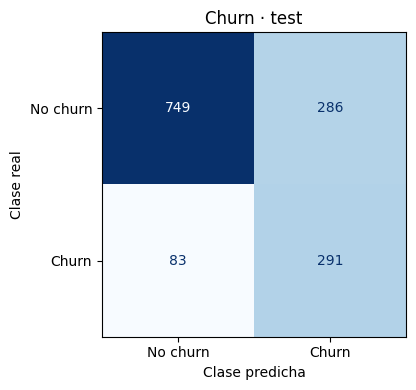

,coef_log_odds,odds_ratio
num__tenure,-0.681,0.506
cat__Contract_Two year,-0.596,0.551
cat__OnlineSecurity_Yes,-0.370,0.691
cat__Contract_One year,-0.366,0.693
cat__TechSupport_Yes,-0.341,0.711
cat__InternetService_No,-0.229,0.795
cat__OnlineSecurity_No internet service,-0.229,0.795
cat__TechSupport_No internet service,-0.229,0.795
num__TotalCharges,-0.109,0.896
cat__PaymentMethod_Credit card (automatic),-0.096,0.909


Referencias categóricas: {'Contract': 'Month-to-month', 'InternetService': 'DSL', 'OnlineSecurity': 'No', 'PaperlessBilling': 'No', 'PaymentMethod': 'Bank transfer (automatic)', 'TechSupport': 'No'}


Bajas detectadas: **291/374**; omitidas: **83**; falsas alertas: **286**. Accuracy de la mayoría: **73.5%**, con recall cero.

In [8]:
baseline_c = pipeline(Xc_train, DummyClassifier(strategy='most_frequent')).fit(Xc_train, yc_train)
filas_c = []
for nombre, modelo in [('Mayoría', baseline_c), ('Logística elegida por CV', ganador_c)]:
    pred = modelo.predict(Xc_test)
    filas_c.append([nombre, accuracy_score(yc_test, pred), precision_score(yc_test, pred, zero_division=0),
                   recall_score(yc_test, pred), f1_score(yc_test, pred, zero_division=0)])
test_c = pd.DataFrame(filas_c, columns=['modelo', 'accuracy', 'precision', 'recall', 'F1']).set_index('modelo')
display(test_c.round(4))
fig, ax = plt.subplots(figsize=(5, 4))
matriz = ConfusionMatrixDisplay.from_predictions(yc_test, ganador_c.predict(Xc_test),
    display_labels=['No churn', 'Churn'], cmap='Blues', colorbar=False, ax=ax)
ax.set(title='Churn · test', xlabel='Clase predicha', ylabel='Clase real')
fig.tight_layout(); plt.show(); plt.close(fig)
tn, fp, fn, tp = matriz.confusion_matrix.ravel()
coef_c = pd.Series(ganador_c['modelo'].coef_[0],
    index=ganador_c['preparar'].get_feature_names_out(), name='coef_log_odds').sort_values()
display(pd.DataFrame({'coef_log_odds': coef_c, 'odds_ratio': np.exp(coef_c)}).round(3))
print('Referencias categóricas:', {col: valores[0] for col, valores in zip(
    Xc_train.select_dtypes('object').columns.sort_values(),
    ganador_c['preparar'].named_transformers_['cat'][-1].categories_)})
display(Markdown(f"Bajas detectadas: **{tp}/{tp + fn}**; omitidas: **{fn}**; falsas alertas: **{fp}**. "
    f"Accuracy de la mayoría: **{test_c.loc['Mayoría', 'accuracy']:.1%}**, con recall cero."))


### ¿Qué significan estos resultados para Churn?

**La accuracy por sí sola oculta el problema.** Decir que ningún cliente se va
logra **73,46 % de accuracy**, pero no detecta ninguna de las 374 bajas del test.
La logística obtiene **73,81 %**, apenas más, y aun así detecta **291 bajas**.
Su aporte se ve al mirar precision y recall, no solo el porcentaje total de aciertos.

Con el umbral de 0,5, los resultados concretos son:

- **Recall de 77,81 %:** identifica 291 de 374 bajas, aproximadamente 8 de cada 10.
  Las **83 restantes** quedan sin detectar.
- **Precision de 50,43 %:** de las **577 alertas**, 291 corresponden a bajas reales
  y **286 son falsas alertas**. Aproximadamente una de cada dos alertas es correcta.
- **F1 de 0,612:** resume precision y recall mediante su media armónica. Mejora
  frente al cero del baseline, pero no demuestra por sí solo que una campaña sea rentable.

En una aplicación de retención, esto supondría revisar bastantes clientes que no
se fueron para identificar una parte importante de las bajas. Puede ser aceptable
si revisar una alerta cuesta poco y perder un cliente cuesta mucho. Si cada alerta
implica un descuento caro, las falsas alertas pueden pesar más. Faltan esos costos
para elegir un umbral de negocio; cualquier ajuste se validaría dentro de train.
Además, detectar una baja no demuestra que una intervención logre evitarla.

**¿Qué nos dicen los coeficientes?** Manteniendo los otros predictores constantes,
un contrato de dos años tiene unas **odds de churn 0,55 veces** las de uno mensual
en el modelo. Una desviación estándar más de antigüedad (`tenure`) se asocia con
unas odds de **0,51 veces**. Las odds son la razón entre la probabilidad de baja y
la de permanencia: reducirlas a la mitad no equivale a reducir a la mitad la
probabilidad. Estos resultados describen asociaciones, no prueban que cambiar el
contrato cause una reducción de bajas. La ponderación balanceada tampoco garantiza
que las probabilidades predichas estén calibradas.


## 4. Conclusiones y límites

En **Housing**, los modelos superan claramente a predecir siempre la media, pero
mantienen un error absoluto medio cercano a **USD 50.700**. Ridge y Lasso no muestran
una ventaja relevante sobre la regresión lineal con estas variables y parámetros.
En **Churn**, la logística detecta cerca del **78 % de las bajas**, a cambio de que
casi la mitad de sus alertas sean falsas. El valor práctico depende del costo de
esas alertas y de las bajas que quedan sin detectar.

Las métricas responden preguntas distintas: RMSE y MAE miden errores de precio;
precision y recall ayudan a evaluar las consecuencias de clasificar clientes.
Por eso no podemos comparar directamente un RMSE con una accuracy para decidir
cuál de las dos misiones tiene un «mejor modelo».

La selección de modelos y parámetros usa CV en train; después de observar test
no reajustamos los modelos. Los mejores puntajes de CV pueden ser optimistas por
la búsqueda de parámetros. Las cifras comentadas corresponden a esta ejecución,
con semilla 42 y los CSV locales.

- **Housing:** conservamos los precios topados y no conocemos su valor sin ese
  límite. La división aleatoria entre zonas no prueba generalización espacial o temporal.
- **Churn:** es una clasificación retrospectiva de un dataset de muestra. Sin fechas
  que prueben la disponibilidad previa de los predictores, no afirmamos anticipación futura.
- **Siguiente paso:** para Housing, probar variables derivadas y validación por zonas;
  para Churn, definir costos y evaluar umbrales dentro de train. Si las decisiones se
  toman después de este análisis, hará falta un nuevo conjunto independiente para
  evaluar la versión final sin reutilizar este test como criterio de selección.
